# Ejercicio 2: Simulación de un único rayo binario

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

a) Implementamos la función `mascara_rayo(n, direccion, s)`, que devuelva una matriz M<sub>r</sub> ∈ {0, 1}<sup>n×n</sup> con un 1 en los píxeles seleccionados por el rayo *r* y un 0 en los restantes.

In [ ]:
def mascara_rayo(n, direccion, s):
  res = np.zeros((n, n))                                                                        # Inicializamos una matriz de ceros
  for i in range(0, n):                                                                         # Por cada fila
    for j in range(0, n):                                                                       # Por cada columna
      if direccion[0] * i + direccion[1] * j == s:                                              # Vemos si está en el centro
        res[i, j] = 1                                                                           # Modificamos

  return res

b) Visualizamos las máscaras para las direcciones (1, 0), (0, 1), (1, 1), (1, −1) y (2, 1), utilizando respectivamente los desplazamientos *s* = 0, 3, 5, 7, 8.

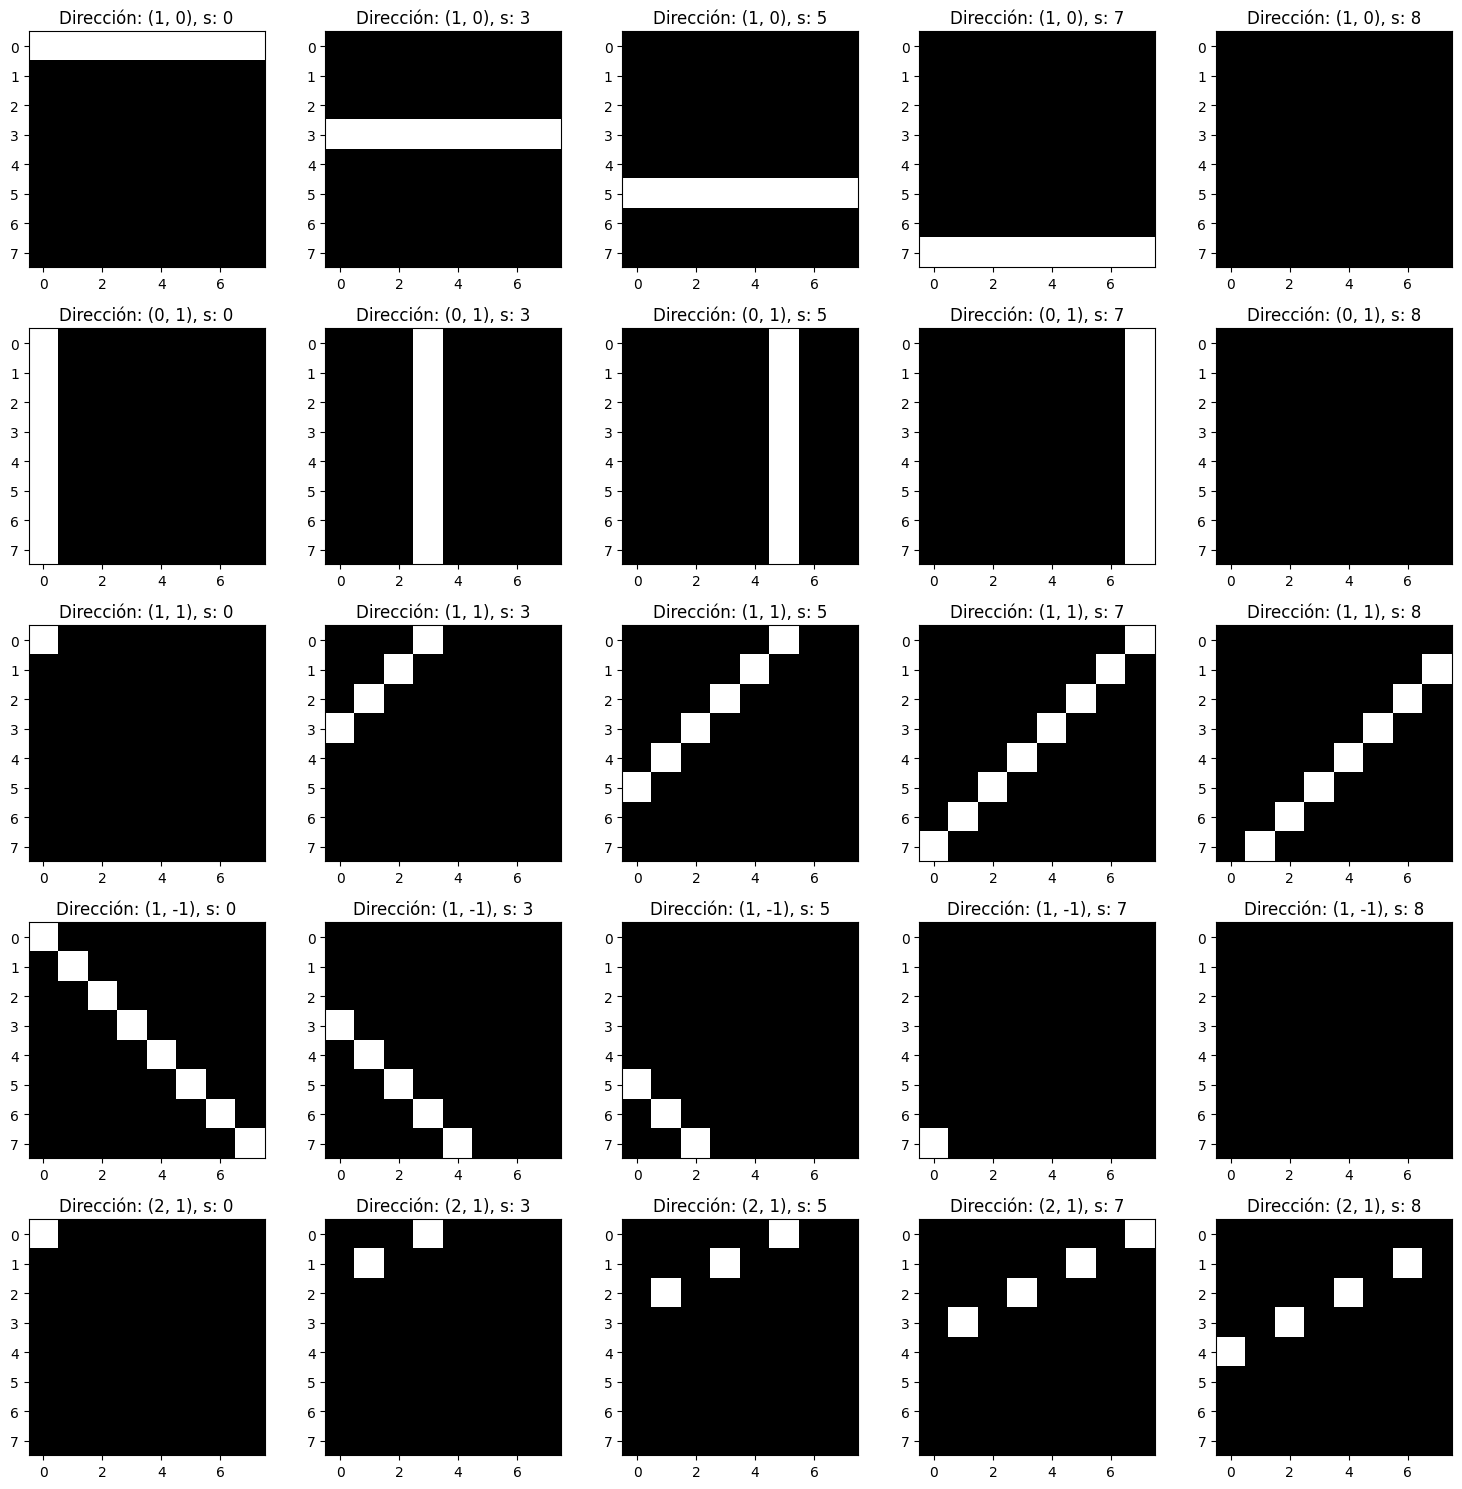

In [ ]:
direcciones = [(1, 0), (0, 1), (1, 1), (1, -1), (2, 1)]
eses = [0, 3, 5, 7, 8]

mascaras = []                                                                                   # Útil para el próximo inciso

num_direcciones = len(direcciones)
num_eses = len(eses)

fig, ax = plt.subplots(num_direcciones, num_eses, figsize=(num_eses * 3, num_direcciones * 3))  # Subplots para mejor visualización de las combinaciones

for r_idx, direccion in enumerate(direcciones):
    for c_idx, s in enumerate(eses):
        mascara = mascara_rayo(8, direccion, s)                                                 # n = 8 por las dimensiones del fantoma del ejercicio anterior (8x8)

        mascaras.append(mascara)

        ax[r_idx, c_idx].imshow(mascara, cmap='gray')
        ax[r_idx, c_idx].set_title(f"Dirección: {direccion}, s: {s}")

plt.tight_layout()
plt.show()

c) Calculamos la medición *b<sub>r</sub>* mediante un producto componente a componente entre la máscara y el fantoma.

In [ ]:
br = []

for mascara in mascaras:
  producto = np.multiply(X_fantoma, mascara)
  br.append(np.sum(producto))

print(br)

[np.float64(0.0), np.float64(2.3), np.float64(2.4), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(2.3), np.float64(2.4), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(1.6), np.float64(2.2), np.float64(1.2), np.float64(1.5), np.float64(1.9000000000000001), np.float64(0.8999999999999999), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(1.1), np.float64(1.4000000000000001), np.float64(1.1)]


d) Dos rayos con distinta orientación pueden producir el mismo *b<sub>r</sub>* porque estos arriban a su sensor con una intensidad idéntica, es decir, la absorción de los rayos X en el trayecto a través del objeto fue la misma.